In [8]:
TESTRETURN1 =["BTCUSDT", "ETHUSDT", "XRPUSDT", "SOLUSDT"]
LOOKBACKWINDOW = 12 * 24 * 30 # 12 * 5min Kerzen= 1h | gesamt lookback in anzahl der Kerzen
STARTDATE = "2025-01-01"

# --- Basket-Konfiguration (gleiche Werte wie 01_baskets.ipynb / 04_residual_pointclouds.ipynb) ---
BASKET_LOOKBACK_DAYS = 7
BASKET_UPPER_BOUNDS = [100_000_000, 250_000_000, 1_000_000_000]

In [9]:
# =========================
# Imports & Pfade
# =========================
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../02_tda_clustering").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
from statsmodels.tsa.stattools import coint, adfuller, kpss
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant
from statsmodels.tools.sm_exceptions import InterpolationWarning

from config import (
    OHLCV_DIR, ASSETS_PATH, ASSET_DAILY_PATH,
    DATE_COL, ASSET_ID_COL, VOLUME_COL,
)
from helperfunctions import HelperFunctions, STABLECOIN_SYMBOLS

helper = HelperFunctions()

print("Imports OK")

Imports OK


In [10]:
# =========================
# Basket-Daten laden (gleiche Quelle wie 01_baskets.ipynb)
# =========================
assets_df = pd.read_parquet(ASSETS_PATH)
asset_daily_df = pd.read_parquet(ASSET_DAILY_PATH)
asset_daily_df[DATE_COL] = pd.to_datetime(asset_daily_df[DATE_COL])

# Stablecoins gehören nicht in eine Mean-Reversion-Spread-Analyse (siehe
# helperfunctions.STABLECOIN_SYMBOLS-Begründung: kein Preissignal, würden
# triviale Kointegration mit sich selbst erzeugen)
_stablecoin_ids = set(assets_df.loc[assets_df["symbol"].isin(STABLECOIN_SYMBOLS), "asset_id"])
asset_daily_df = asset_daily_df.loc[~asset_daily_df[ASSET_ID_COL].isin(_stablecoin_ids)].copy()

rolling_volume_df = helper.compute_rolling_volume_table(
    asset_daily_df,
    id_column=ASSET_ID_COL,
    date_column=DATE_COL,
    volume_column=VOLUME_COL,
    lookback_days=BASKET_LOOKBACK_DAYS,
)

BASKET_LABELS = [f"Basket {n}" for n in range(1, len(BASKET_UPPER_BOUNDS) + 2)]

_available_dates = sorted(rolling_volume_df[DATE_COL].dropna().unique())
BASKET_AVAILABLE_DATES = [pd.Timestamp(d) for d in _available_dates]


def resolve_market_symbols(asset_ids: list[int]) -> list[str]:
    """Übersetzt asset_id -> binance_symbol (market_symbol), überspringt Assets
    ohne aufgelöstes Binance-Symbol (siehe 01_assets.ipynb resolve_binance_symbol)."""
    lookup = assets_df.set_index("asset_id")["binance_symbol"]
    symbols = lookup.reindex(asset_ids).dropna().tolist()
    return symbols


print(f"assets_df: {assets_df.shape}  |  asset_daily_df (ohne Stablecoins): {asset_daily_df.shape}")
print(f"Basket-Labels: {BASKET_LABELS}")
print(f"Verfügbare Daten: {BASKET_AVAILABLE_DATES[0].date()} → {BASKET_AVAILABLE_DATES[-1].date()}")

assets_df: (57, 9)  |  asset_daily_df (ohne Stablecoins): (28769, 5)
Basket-Labels: ['Basket 1', 'Basket 2', 'Basket 3', 'Basket 4']
Verfügbare Daten: 2024-07-23 → 2026-07-23


In [11]:
# =========================
# Preisdaten laden
# =========================
def load_close_prices(tickers: list[str], start_date: str, n_candles: int) -> pd.DataFrame:
    """Lädt close-Preise für die gegebenen Ticker ab start_date, begrenzt auf
    n_candles Kerzen (LOOKBACKWINDOW). Liest nur die dafür nötigen Monatsdateien.

    Falls ab start_date weniger als n_candles Kerzen tatsächlich vorhanden sind
    (z.B. start_date liegt zu nah am Ende der verfügbaren OHLCV-Historie), wird
    NICHT auf die volle Fenstergrösse bestanden -- es werden einfach so viele
    Kerzen wie vorhanden zurückgegeben. Die aufrufende Stelle sollte prüfen, ob
    das Ergebnis für die geplante Analyse ausreichend lang ist.

    Args:
        tickers: Liste von market_symbol-Strings, z.B. ["BTCUSDT", "ETHUSDT"].
        start_date: Startdatum (inklusive), z.B. "2025-01-01".
        n_candles: Maximale Anzahl 5min-Kerzen ab start_date pro Ticker.

    Returns:
        DataFrame (timestamp x ticker) mit close-Preisen, NaN-Zeilen entfernt
        (nur Zeitstempel, an denen alle Ticker einen Wert haben). Kann weniger
        als n_candles Zeilen haben, siehe oben.
    """
    start_ts = pd.Timestamp(start_date, tz="UTC")
    # grobe Obergrenze fürs Enddatum, ausreichend für n_candles à 5min
    end_ts = start_ts + pd.Timedelta(minutes=5 * n_candles) + pd.Timedelta(days=2)

    months = pd.date_range(start_ts.normalize(), end_ts.normalize(), freq="MS")
    files = sorted({OHLCV_DIR / f"ohlcv_{m.year:04d}-{m.month:02d}.parquet" for m in months})
    files = [f for f in files if f.exists()]
    if not files:
        raise FileNotFoundError(f"Keine OHLCV-Dateien für Zeitraum ab {start_date} gefunden.")

    frames = []
    for f in files:
        df = pd.read_parquet(f, columns=["timestamp", "market_symbol", "close"])
        df = df[df["market_symbol"].isin(tickers)]
        frames.append(df)

    raw = pd.concat(frames, ignore_index=True)
    raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)
    raw = raw[raw["timestamp"] >= start_ts]

    price_matrix = (
        raw.pivot_table(index="timestamp", columns="market_symbol", values="close", aggfunc="last")
        .sort_index()
    )

    missing = [t for t in tickers if t not in price_matrix.columns]
    if missing:
        print(f"⚠️  Keine Daten gefunden für: {missing}")

    price_matrix = price_matrix.dropna(axis=0, how="any")
    price_matrix = price_matrix.iloc[:n_candles]
    return price_matrix


close_prices = load_close_prices(TESTRETURN1, STARTDATE, LOOKBACKWINDOW)
print(f"Preismatrix: {close_prices.shape[0]} Kerzen x {close_prices.shape[1]} Ticker")
print(f"Zeitraum: {close_prices.index.min()} → {close_prices.index.max()}")
display(close_prices.head())

Preismatrix: 8640 Kerzen x 4 Ticker
Zeitraum: 2025-01-01 00:00:00+00:00 → 2025-01-30 23:55:00+00:00


market_symbol,BTCUSDT,ETHUSDT,SOLUSDT,XRPUSDT
timestamp,,,,
2025-01-01 00:00:00+00:00,93661.20,3340.26,189.85,2.0844
2025-01-01 00:05:00+00:00,93607.10,3342.99,190.02,2.0927
2025-01-01 00:10:00+00:00,93656.18,3348.50,190.51,2.0967
2025-01-01 00:15:00+00:00,93796.35,3351.05,191.00,2.0983
2025-01-01 00:20:00+00:00,93740.00,3349.33,190.66,2.0974


## Legende — Spalten der Spread-Diagnostik-Tabelle

Die folgende Tabelle (`analyze_mean_reversion()` / `compute_all_spread_diagnostics()`)
prüft für jedes Tickerpaar, ob deren **Preis-Level-Spread** —
`spread_t = log(P1_t) - hedge_ratio · log(P2_t)` — mean-revertierend ist.

| Spalte | Bedeutung |
|---|---|
| `ticker_1`, `ticker_2` | Die beiden Ticker des getesteten Paares. |
| `hedge_ratio` | Gewicht β von `ticker_2` im Spread, per OLS-Regression `log(P1) = α + β·log(P2) + ε` geschätzt (CADF-Stil, Chan 2013). Bestimmt, wie stark `ticker_2` in den Spread eingeht. |
| `adf_pvalue` | p-Wert des Augmented-Dickey-Fuller-Tests. H0 = Spread hat eine Unit Root (nicht stationär). **Niedriger p-Wert ⇒ stationär / mean-revertierend.** |
| `adf_stationary` | `True`, wenn `adf_pvalue < α` (Standard α = 0.05) — ADF spricht für Stationarität. |
| `kpss_pvalue` | p-Wert des KPSS-Tests. H0 = Spread ist stationär (umgekehrte Nullhypothese zu ADF, dient als Gegenprobe). **Hoher p-Wert ⇒ stationär.** |
| `kpss_stationary` | `True`, wenn `kpss_pvalue >= α` — KPSS spricht für Stationarität. |
| `kpss_capped` | `True`, wenn die KPSS-Teststatistik ausserhalb von statsmodels' Nachschlagetabelle lag; der angezeigte `kpss_pvalue` ist dann der nächstgelegene Tabellen-Grenzwert, nicht der exakte Wert. Ändert nichts an `kpss_stationary`. |
| `hurst` | Hurst-Exponent (Rescaled-Range-Analyse). **H < 0.5** = anti-persistent/mean-revertierend, **H = 0.5** = Random Walk, **H > 0.5** = trendfolgend. |
| `half_life_periods` | Halbwertszeit der Rückkehr zum Mittelwert (Ornstein-Uhlenbeck-Fit), in Anzahl 5-Minuten-Kerzen. Niedriger Wert = schnellere Mean-Reversion. `inf`, falls keine Mean-Reversion nachweisbar. |
| `mean_reverting` | Kombiniertes Gesamturteil: `True`, wenn ADF **und** KPSS beide für Stationarität sprechen **und** `hurst < 0.5` — robuster als ein einzelner Test allein (ADF hat bekanntermassen schwache Power). |

Die Tabelle ist absteigend nach `mean_reverting` und aufsteigend nach `half_life_periods`
sortiert — die am stärksten und schnellsten mean-revertierenden Paare stehen oben.

ℹ️  Bei 6/6 Paaren lag die KPSS-Teststatistik ausserhalb der Nachschlagetabelle — der angezeigte kpss_pvalue ist der nächstgelegene Tabellen-Grenzwert, nicht der exakte Wert. Die Stationaritäts-Einstufung (kpss_stationary) bleibt davon unberührt.
Getestete Ticker: ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'XRPUSDT']
Kerzen im Fenster: 8640  |  Zeitraum: 2025-01-01 00:00:00+00:00 → 2025-01-30 23:55:00+00:00

Spread-Diagnostik (spread_t = log(P1) - hedge_ratio*log(P2), alle Paare, sortiert nach Half-Life):


,ticker_1,ticker_2,hedge_ratio,adf_pvalue,adf_stationary,kpss_pvalue,kpss_stationary,kpss_capped,hurst,half_life_periods,mean_reverting
0,BTCUSDT,SOLUSDT,0.3345,0.0162,True,0.0100,False,True,0.4507,189.5,False
1,BTCUSDT,XRPUSDT,0.2691,0.1296,False,0.0100,False,True,0.4803,342.0,False
2,ETHUSDT,XRPUSDT,-0.1058,0.0658,False,0.0100,False,True,0.5162,411.8,False
3,ETHUSDT,SOLUSDT,0.0030,0.1673,False,0.0100,False,True,0.5221,586.8,False
4,BTCUSDT,ETHUSDT,0.0207,0.3271,False,0.0100,False,True,0.4827,807.3,False
5,SOLUSDT,XRPUSDT,0.6712,0.3665,False,0.0100,False,True,0.4663,868.6,False


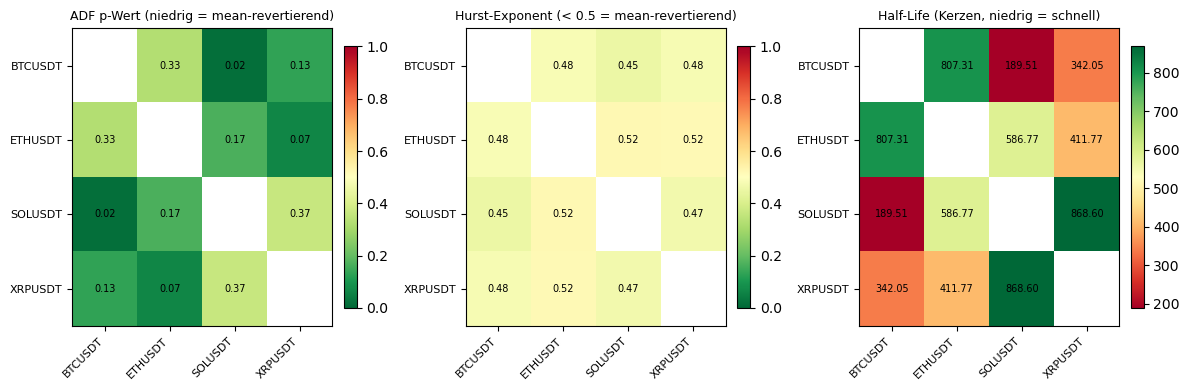


0/6 Paare sind robust mean-revertierend (ADF UND KPSS stimmen überein UND Hurst < 0.5, α=0.05).


In [12]:
# =========================
# Schritt 1 — Mean-Reversion-Validierung pro Spread
# =========================
# Intra-Cluster-Spread nach Lin et al. (2021) für die spätere Signalgenerierung:
# Rt = r_Ai,t - r_Aj,t (Log-Return-Differenz). Für die Stationaritätsprüfung
# (ADF/KPSS/Hurst/Half-Life) ist DIESE Reihe aber ungeeignet, da Renditen
# bereits log-differenziert sind und ihre Differenz dadurch fast immer trivial
# stationär ist -- unabhängig davon, ob zwischen den Assets eine echte
# ökonomische Beziehung besteht (siehe Bug-Analyse: ADF p=0.0000 über alle
# Paare, Hurst nahe 0, Half-Life < 1 Kerze -> ökonomisch unplausibel).
#
# Die Chan-Toolbox (2013) prüft Mean-Reversion stattdessen auf der PREIS-Ebene
# (Level, wie auch bereits analyze_cluster_mean_reversion()/build_cluster_spread()
# weiter unten im Notebook es tun): spread_t = log(P1_t) - hedge_ratio*log(P2_t),
# mit hedge_ratio aus einer OLS-Regression log(P1) = alpha + beta*log(P2) + eps
# (CADF-Stil). Diese Preis-Level-Spread-Reihe ist die korrekte Eingabe für
# ADF, KPSS, Hurst-Exponent und Half-Life.

def compute_log_returns(price_df: pd.DataFrame) -> pd.DataFrame:
    """Log-Returns pro Ticker: r_t = log(P_t / P_t-1). Erste Zeile ist NaN -> dropna.

    Wird für die SPÄTERE Lin-et-al.-Signalgenerierung (Rt = r_i - r_j) benötigt,
    NICHT für die Stationaritätsdiagnostik in diesem Abschnitt."""
    return np.log(price_df / price_df.shift(1)).dropna(how="any")


def compute_return_spread(returns_df: pd.DataFrame, ticker_1: str, ticker_2: str) -> pd.Series:
    """Rt = r_Ai,t - r_Aj,t -- die Intra-Cluster-Spread-Zeitreihe für die
    Lin-et-al.-Signalgenerierung. NICHT für ADF/KPSS/Hurst/Half-Life verwenden
    (siehe compute_price_spread)."""
    return returns_df[ticker_1] - returns_df[ticker_2]


def estimate_hedge_ratio(price_df: pd.DataFrame, ticker_1: str, ticker_2: str) -> float:
    """Schätzt die Hedge-Ratio per OLS (CADF-Stil, Chan 2013):
    log(P1) = alpha + beta * log(P2) + eps
    beta ist die Hedge-Ratio, mit der ticker_2 gewichtet wird, um den
    stationärsten Preis-Spread gegen ticker_1 zu bilden.

    Args:
        price_df: DataFrame (timestamp x ticker) mit rohen close-Preisen.
        ticker_1, ticker_2: die beiden Ticker der Regression.

    Returns:
        Geschätzte Hedge-Ratio beta (float).
    """
    log_p1 = np.log(price_df[ticker_1]).to_numpy()
    log_p2 = np.log(price_df[ticker_2]).to_numpy()

    x = add_constant(log_p2)
    model = OLS(log_p1, x).fit()
    return float(model.params[1])


def compute_price_spread(price_df: pd.DataFrame, ticker_1: str, ticker_2: str, hedge_ratio: float = 1.0) -> pd.Series:
    """Spread auf Preis-Ebene (Level), nicht auf Renditen-Ebene:
    spread_t = log(P1_t) - hedge_ratio * log(P2_t)
    Das ist die Reihe, auf die ADF/KPSS/Hurst/Half-Life angewendet werden müssen,
    NICHT die Renditedifferenz r1_t - r2_t (die ist trivial stationär)."""
    log_p1 = np.log(price_df[ticker_1])
    log_p2 = np.log(price_df[ticker_2])
    return log_p1 - hedge_ratio * log_p2


def hurst_exponent(series: np.ndarray, max_lag: int = 100) -> float:
    """Hurst-Exponent via Rescaled-Range-Analyse (R/S), wie in der Chan-Toolbox.

    H < 0.5  -> mean-revertierend (anti-persistent)
    H = 0.5  -> Random Walk
    H > 0.5  -> trendfolgend (persistent)

    Implementiert die klassische R/S-Methode selbst (keine Zusatz-Dependency):
    für eine Reihe von Lags tau wird die Standardabweichung der tau-Differenzen
    berechnet; die Steigung von log(std) gegen log(tau) in einer linearen
    Regression ist der Hurst-Exponent (Var(dY) ~ tau^(2H) -> std ~ tau^H).

    Args:
        series: 1D-Array der Zeitreihe (z.B. Preis-Level-Spread).
        max_lag: Maximaler Lag tau, der einbezogen wird.

    Returns:
        Geschätzter Hurst-Exponent (float).
    """
    series = np.asarray(series)
    lags = range(2, min(max_lag, len(series) // 2))

    tau = [np.std(series[lag:] - series[:-lag]) for lag in lags]
    tau = np.array(tau)
    lags = np.array(list(lags))

    valid = tau > 0
    poly = np.polyfit(np.log(lags[valid]), np.log(tau[valid]), 1)
    return float(poly[0])


def compute_half_life(series: pd.Series) -> float:
    """Half-Life eines Ornstein-Uhlenbeck-Prozesses, aus derselben Regression
    wie beim ADF-Test: Δy(t) = λ*y(t-1) + μ + ε -> Half-Life = -ln(2)/λ.

    λ < 0 wird für Mean-Reversion erwartet (je negativer, desto schneller die
    Rückkehr zum Mittelwert); λ >= 0 ergibt keine sinnvolle (endliche,
    positive) Half-Life -> np.inf.

    Args:
        series: 1D-Zeitreihe (z.B. Preis-Level-Spread), muss stationär genug
            für eine sinnvolle Interpretation sein.

    Returns:
        Half-Life in Anzahl Perioden (Kerzen), oder np.inf falls λ >= 0.
    """
    y = series.to_numpy()
    y_lag = y[:-1]
    y_diff = np.diff(y)

    x = add_constant(y_lag)
    model = OLS(y_diff, x).fit()
    lam = model.params[1]

    if lam >= 0:
        return float("inf")
    return float(-np.log(2) / lam)


def analyze_spread_stationarity(price_df: pd.DataFrame, ticker_1: str, ticker_2: str, alpha: float = 0.05) -> dict:
    """Führt alle vier Chan-Toolbox-Tests auf dem PREIS-Level-Spread eines
    Tickerpaars aus (nicht auf der Renditedifferenz, siehe Modulkommentar oben).

    Args:
        price_df: DataFrame (timestamp x ticker) mit rohen close-Preisen.
        ticker_1, ticker_2: die beiden Ticker des Spreads
            spread_t = log(P1_t) - hedge_ratio*log(P2_t).
        alpha: Signifikanzniveau für ADF/KPSS (Standard 5 %).

    Returns:
        Dict mit hedge_ratio, adf_pvalue, adf_stationary (bool), kpss_pvalue,
        kpss_stationary (bool), kpss_capped (bool, siehe unten), hurst,
        half_life_periods, sowie einem kombinierten "mean_reverting"-Flag
        (ADF und KPSS stimmen überein UND Hurst < 0.5).

        kpss_capped=True bedeutet: die KPSS-Teststatistik lag ausserhalb von
        statsmodels' Nachschlagetabelle, der zurückgegebene p-Wert ist der
        nächstgelegene Tabellen-Grenzwert (nicht der exakte Wert). Das ändert
        NICHTS an kpss_stationary, da diese bereits korrekt aus dem gekappten
        Wert abgeleitet wird -- kpss_capped dient nur der Transparenz.
    """
    hedge_ratio = estimate_hedge_ratio(price_df, ticker_1, ticker_2)
    spread = compute_price_spread(price_df, ticker_1, ticker_2, hedge_ratio)

    adf_pvalue = adfuller(spread)[1]
    adf_stationary = adf_pvalue < alpha  # ADF: H0 = Unit Root -> p < alpha heisst stationär

    # KPSS: H0 = stationär -> p < alpha heisst NICHT stationär (umgekehrte Logik zu ADF).
    # Die Teststatistik liegt bei kurzen/stark trend- oder mean-revertierenden Reihen
    # häufig ausserhalb der Nachschlagetabelle -> statsmodels warnt dann per
    # InterpolationWarning und kappt den p-Wert auf den nächsten Tabellenrand. Diese
    # Warnung wird hier abgefangen (nicht einzeln pro Paar ausgegeben) und stattdessen
    # als kpss_capped-Flag zurückgegeben; compute_all_spread_diagnostics fasst das
    # für alle Paare in einer einzigen, verständlichen Meldung zusammen.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", InterpolationWarning)
        kpss_stat, kpss_pvalue, _, _ = kpss(spread, regression="c", nlags="auto")
    kpss_capped = any(issubclass(w.category, InterpolationWarning) for w in caught)
    kpss_stationary = kpss_pvalue >= alpha

    hurst = hurst_exponent(spread.to_numpy())
    half_life = compute_half_life(spread)

    # Übereinstimmende Diagnose beider Tests + Hurst < 0.5 als robusteres Gesamturteil,
    # da ADF bekanntermassen schwache Power hat (Lin et al. / Chan 2013).
    mean_reverting = adf_stationary and kpss_stationary and hurst < 0.5

    return {
        "ticker_1": ticker_1,
        "ticker_2": ticker_2,
        "hedge_ratio": hedge_ratio,
        "adf_pvalue": adf_pvalue,
        "adf_stationary": adf_stationary,
        "kpss_pvalue": kpss_pvalue,
        "kpss_stationary": kpss_stationary,
        "kpss_capped": kpss_capped,
        "hurst": hurst,
        "half_life_periods": half_life,
        "mean_reverting": mean_reverting,
    }


def compute_all_spread_diagnostics(price_df: pd.DataFrame, alpha: float = 0.05) -> pd.DataFrame:
    """Wendet analyze_spread_stationarity auf alle Tickerpaare an (alle mit allen),
    auf Basis der Preis-Level-Spreads (siehe Modulkommentar oben).

    Args:
        price_df: DataFrame (timestamp x ticker) mit rohen close-Preisen.
        alpha: Signifikanzniveau für ADF/KPSS.

    Returns:
        Lange Tabelle, ein Zeile pro Paar, sortiert nach Half-Life aufsteigend
        (schnellste Mean-Reversion zuerst); mean_reverting=False Paare am Ende.
    """
    tickers = price_df.columns.tolist()

    rows = []
    for i, t1 in enumerate(tickers):
        for j, t2 in enumerate(tickers):
            if j <= i:
                continue
            rows.append(analyze_spread_stationarity(price_df, t1, t2, alpha=alpha))

    diagnostics_df = pd.DataFrame(rows)
    diagnostics_df = diagnostics_df.sort_values(
        ["mean_reverting", "half_life_periods"], ascending=[False, True]
    ).reset_index(drop=True)

    n_capped = int(diagnostics_df["kpss_capped"].sum())
    if n_capped > 0:
        print(f"ℹ️  Bei {n_capped}/{len(diagnostics_df)} Paaren lag die KPSS-Teststatistik ausserhalb "
              f"der Nachschlagetabelle — der angezeigte kpss_pvalue ist der nächstgelegene "
              f"Tabellen-Grenzwert, nicht der exakte Wert. Die Stationaritäts-Einstufung "
              f"(kpss_stationary) bleibt davon unberührt.")

    return diagnostics_df


def plot_spread_diagnostics_heatmaps(diagnostics_df: pd.DataFrame, tickers: list[str]) -> None:
    """Drei Heatmaps nebeneinander: ADF p-Wert, Hurst-Exponent, Half-Life (Kerzen)."""
    metrics = [
        ("adf_pvalue", "ADF p-Wert (niedrig = mean-revertierend)", "RdYlGn_r", 0, 1),
        ("hurst", "Hurst-Exponent (< 0.5 = mean-revertierend)", "RdYlGn_r", 0, 1),
        ("half_life_periods", "Half-Life (Kerzen, niedrig = schnell)", "RdYlGn", None, None),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(max(12, len(tickers) * 2.5), max(4, len(tickers) * 0.8)))

    for ax, (col, title, cmap, vmin, vmax) in zip(axes, metrics):
        matrix = pd.DataFrame(np.nan, index=tickers, columns=tickers, dtype=float)
        for _, row in diagnostics_df.iterrows():
            val = row[col]
            val = val if np.isfinite(val) else np.nan
            matrix.loc[row["ticker_1"], row["ticker_2"]] = val
            matrix.loc[row["ticker_2"], row["ticker_1"]] = val

        plot_vmax = vmax if vmax is not None else np.nanmax(matrix.values)
        plot_vmin = vmin if vmin is not None else np.nanmin(matrix.values)

        im = ax.imshow(matrix.values, vmin=plot_vmin, vmax=plot_vmax, cmap=cmap, aspect="auto")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xticks(range(len(tickers))); ax.set_xticklabels(tickers, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(len(tickers))); ax.set_yticklabels(tickers, fontsize=8)
        ax.set_title(title, fontsize=9)

        for r in range(len(tickers)):
            for c in range(len(tickers)):
                val = matrix.values[r, c]
                if not np.isnan(val):
                    ax.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=7)

    plt.tight_layout()
    plt.show()


def analyze_mean_reversion(tickers: list[str], start_date: str, n_candles: int, alpha: float = 0.05) -> pd.DataFrame:
    """Kompletter Analyse-Durchlauf für eine beliebige Ticker-Liste: lädt Preise,
    bildet für jedes Paar den Preis-Level-Spread (Hedge-Ratio-gewichtet) und
    testet ihn mit ADF, KPSS, Hurst-Exponent und Half-Life. Zeigt
    Übersichtstabelle + Heatmaps. Das ist der Einstiegspunkt, der später mit
    einer beliebigen Ticker-Liste aufgerufen wird.

    Args:
        tickers: Liste von market_symbol-Strings.
        start_date: Startdatum des Lookback-Fensters.
        n_candles: Fenstergrösse in Anzahl Kerzen.
        alpha: Signifikanzniveau für ADF/KPSS (Standard 5 %).

    Returns:
        Die lange, sortierte Diagnose-Tabelle (siehe compute_all_spread_diagnostics).
    """
    prices = load_close_prices(tickers, start_date, n_candles)
    diagnostics_df = compute_all_spread_diagnostics(prices, alpha=alpha)

    print(f"Getestete Ticker: {list(prices.columns)}")
    print(f"Kerzen im Fenster: {len(prices)}  |  Zeitraum: {prices.index.min()} → {prices.index.max()}")

    print(f"\nSpread-Diagnostik (spread_t = log(P1) - hedge_ratio*log(P2), alle Paare, sortiert nach Half-Life):")
    display(
        diagnostics_df.style.format({
            "hedge_ratio": "{:.4f}",
            "adf_pvalue": "{:.4f}",
            "kpss_pvalue": "{:.4f}",
            "hurst": "{:.4f}",
            "half_life_periods": "{:.1f}",
        })
    )

    plot_spread_diagnostics_heatmaps(diagnostics_df, list(prices.columns))

    n_mean_reverting = diagnostics_df["mean_reverting"].sum()
    print(f"\n{n_mean_reverting}/{len(diagnostics_df)} Paare sind robust mean-revertierend "
          f"(ADF UND KPSS stimmen überein UND Hurst < 0.5, α={alpha}).")

    if n_mean_reverting > 0:
        median_half_life = diagnostics_df.loc[diagnostics_df["mean_reverting"], "half_life_periods"].median()
        print(f"Median Half-Life dieser Paare: {median_half_life:.1f} Kerzen "
              f"(~{median_half_life * 5 / 60:.1f} Stunden bei 5min-Kerzen) "
              f"— sollte das Lookback-Fenster für die Tolerance-Interval-Berechnung kalibrieren, "
              f"statt es willkürlich zu setzen (vgl. Lin et al., 60/80/100-Tage-Fenster).")

    return diagnostics_df


# --- Testlauf mit TESTRETURN1 ---
pairs_result = analyze_mean_reversion(TESTRETURN1, STARTDATE, LOOKBACKWINDOW)

Getestete Ticker: ['BTCUSDT', 'ETHUSDT', 'SOLUSDT', 'XRPUSDT']
Kerzen im Fenster: 8640  |  Zeitraum: 2025-01-01 00:00:00+00:00 → 2025-01-30 23:55:00+00:00

Johansen Trace-Test (H0: höchstens r Kointegrationsbeziehungen):


,r (Rang),Trace-Statistik,kritischer Wert (95%),H0 verworfen
0,0,49.15,47.85,True
1,1,24.59,29.80,False
2,2,10.93,15.49,False
3,3,1.35,3.84,False



✅ 1 signifikante Kointegrationsbeziehung(en) gefunden (α=0.05) — das Cluster besitzt mindestens einen gemeinsamen Mean-Reversion-Anker.

Kointegrationsvektoren (Gewichte pro Beziehung, stärkste zuerst):


,relation_1
BTCUSDT,91.9111
ETHUSDT,-9.4025
SOLUSDT,-22.3696
XRPUSDT,-10.8655



Cluster-Spread (stärkste Beziehung) — ADF-Test auf Stationarität: p-Wert = 0.0015


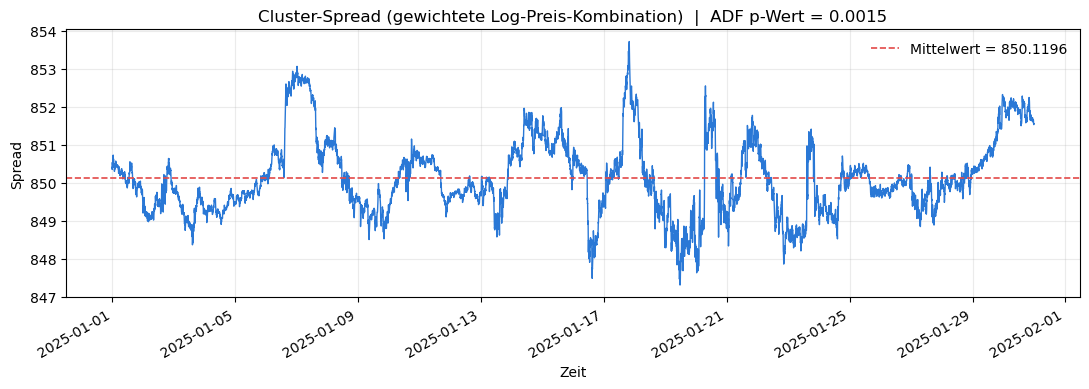

In [13]:
# =========================
# Cluster-weite Mean-Reversion (Johansen-Kointegrationstest)
# =========================
# Kritische Werte des Johansen-Tests (Trace-Statistik) von statsmodels, für die
# gebräuchlichen Signifikanzniveaus. Reihenfolge der Spalten in cvt: 90%, 95%, 99%.
_JOHANSEN_SIG_COLUMNS = {0.10: 0, 0.05: 1, 0.01: 2}


def compute_johansen_test(price_df: pd.DataFrame, det_order: int = 0, k_ar_diff: int = 1) -> dict:
    """Johansen-Kointegrationstest über alle Ticker gleichzeitig (Log-Preise).

    Anders als der paarweise Engle-Granger-Test prüft Johansen, ob es unter der
    GESAMTEN Gruppe von Tickern eine oder mehrere stationäre Linearkombinationen
    (Kointegrationsbeziehungen) gibt -- also ob sich ein oder mehrere gemeinsame
    "Anker" bilden, zu denen das ganze Cluster mean-revertiert, statt nur einzelne
    Paare separat zu betrachten. Die Trace-Statistik testet schrittweise die
    Nullhypothese "es gibt höchstens r Kointegrationsbeziehungen" für r = 0, 1, ...

    Args:
        price_df: DataFrame (timestamp x ticker) mit rohen close-Preisen.
        det_order: deterministischer Term (0 = konstanter Term in der
            Kointegrationsbeziehung, Standard für Preisreihen).
        k_ar_diff: Anzahl verzögerter Differenzen im zugrundeliegenden VECM
            (Standard 1).

    Returns:
        Dict mit:
            - n_coint_relations (int): Anzahl signifikanter Kointegrations-
              beziehungen bei alpha=5% (0 = kein gemeinsamer Mean-Reversion-Anker
              im Cluster, >=1 = das Cluster als Ganzes ist mean-revertierend)
            - trace_stats, trace_crit_95 (np.ndarray): Trace-Statistik je Rang r
              und der zugehörige 95%-kritische Wert
            - eigenvectors (pd.DataFrame): Kointegrationsvektoren (Spalten =
              Beziehungen, Zeilen = Ticker) -- die Gewichte, mit denen die
              Ticker kombiniert den jeweils stationärsten Spread ergeben
            - result: das rohe statsmodels JohansenTestResult-Objekt
    """
    tickers = price_df.columns.tolist()
    log_prices = np.log(price_df)

    result = coint_johansen(log_prices.to_numpy(), det_order, k_ar_diff)

    trace_stats = result.lr1
    trace_crit_95 = result.cvt[:, _JOHANSEN_SIG_COLUMNS[0.05]]

    n_coint_relations = int(np.sum(trace_stats > trace_crit_95))

    eigenvectors = pd.DataFrame(
        result.evec[:, :len(tickers)],
        index=tickers,
        columns=[f"relation_{i+1}" for i in range(len(tickers))],
    )

    return {
        "n_coint_relations": n_coint_relations,
        "trace_stats": trace_stats,
        "trace_crit_95": trace_crit_95,
        "eigenvectors": eigenvectors,
        "result": result,
    }


def build_cluster_spread(price_df: pd.DataFrame, weights: pd.Series) -> pd.Series:
    """Baut den Cluster-Spread als gewichtete Summe der Log-Preise.

    weights kommt typischerweise aus der ersten Spalte (stärkste Beziehung) von
    compute_johansen_test(...)["eigenvectors"].

    Args:
        price_df: DataFrame (timestamp x ticker) mit rohen close-Preisen.
        weights: Gewichte pro Ticker (Index muss zu price_df.columns passen).

    Returns:
        Zeitreihe des Cluster-Spreads (Series, gleicher Index wie price_df).
    """
    log_prices = np.log(price_df[weights.index])
    return (log_prices * weights).sum(axis=1)


def plot_cluster_spread(spread: pd.Series, adf_pvalue: float) -> None:
    """Plottet den Cluster-Spread mit Mittelwert-Linie, zur visuellen Kontrolle
    der Mean-Reversion (sollte um den Mittelwert oszillieren, nicht driften)."""
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(spread.index, spread.values, color="#2a78d6", linewidth=1)
    ax.axhline(spread.mean(), color="#e34948", linestyle="--", linewidth=1.2, label=f"Mittelwert = {spread.mean():.4f}")
    ax.set_title(f"Cluster-Spread (gewichtete Log-Preis-Kombination)  |  ADF p-Wert = {adf_pvalue:.4f}")
    ax.set_xlabel("Zeit")
    ax.set_ylabel("Spread")
    ax.legend(frameon=False)
    ax.grid(True, alpha=0.25)
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


def analyze_cluster_mean_reversion(tickers: list[str], start_date: str, n_candles: int, alpha: float = 0.05) -> dict:
    """Prüft, ob das GESAMTE Ticker-Cluster gemeinsam mean-revertierend ist
    (Johansen-Test), zusätzlich zur rein paarweisen Betrachtung.

    Args:
        tickers: Liste von market_symbol-Strings.
        start_date: Startdatum des Lookback-Fensters.
        n_candles: Fenstergrösse in Anzahl Kerzen.
        alpha: Signifikanzniveau für die Trace-Statistik (Standard 5 %).

    Returns:
        Dict mit den Johansen-Ergebnissen (siehe compute_johansen_test) plus
        "cluster_spread" (Series) und "spread_adf_pvalue" (float) für die
        stärkste gefundene Kointegrationsbeziehung.
    """
    prices = load_close_prices(tickers, start_date, n_candles)
    johansen = compute_johansen_test(prices)

    print(f"Getestete Ticker: {list(prices.columns)}")
    print(f"Kerzen im Fenster: {len(prices)}  |  Zeitraum: {prices.index.min()} → {prices.index.max()}")

    print(f"\nJohansen Trace-Test (H0: höchstens r Kointegrationsbeziehungen):")
    trace_table = pd.DataFrame({
        "r (Rang)": range(len(tickers)),
        "Trace-Statistik": johansen["trace_stats"],
        "kritischer Wert (95%)": johansen["trace_crit_95"],
        "H0 verworfen": johansen["trace_stats"] > johansen["trace_crit_95"],
    })
    display(trace_table.style.format({"Trace-Statistik": "{:.2f}", "kritischer Wert (95%)": "{:.2f}"}))

    n_rel = johansen["n_coint_relations"]
    if n_rel == 0:
        print(f"\n❌ Keine signifikante Kointegrationsbeziehung gefunden (α={alpha}) — "
              f"das Cluster als Ganzes ist nicht nachweisbar mean-revertierend.")
    else:
        print(f"\n✅ {n_rel} signifikante Kointegrationsbeziehung(en) gefunden (α={alpha}) — "
              f"das Cluster besitzt mindestens einen gemeinsamen Mean-Reversion-Anker.")

    print(f"\nKointegrationsvektoren (Gewichte pro Beziehung, stärkste zuerst):")
    display(johansen["eigenvectors"].iloc[:, :max(1, n_rel)].style.format("{:.4f}"))

    # Spread aus der stärksten Beziehung (erste Spalte) bilden und auf Stationarität prüfen
    strongest_weights = johansen["eigenvectors"].iloc[:, 0]
    cluster_spread = build_cluster_spread(prices, strongest_weights)
    spread_adf_pvalue = adfuller(cluster_spread)[1]

    print(f"\nCluster-Spread (stärkste Beziehung) — ADF-Test auf Stationarität: p-Wert = {spread_adf_pvalue:.4f}")
    plot_cluster_spread(cluster_spread, spread_adf_pvalue)

    johansen["cluster_spread"] = cluster_spread
    johansen["spread_adf_pvalue"] = spread_adf_pvalue
    return johansen


# --- Testlauf mit TESTRETURN1 ---
cluster_result = analyze_cluster_mean_reversion(TESTRETURN1, STARTDATE, LOOKBACKWINDOW)

In [14]:
# =========================
# Interaktiv: Mean-Reversion-Analyse für einen echten Basket an einem Datum
# =========================
# Statt einer fest hartkodierten Ticker-Liste (TESTRETURN1) werden hier die
# tatsächlichen Mitglieder eines Volumen-Baskets an einem gewählten Datum
# (helper.build_volume_baskets, siehe 01_baskets.ipynb) verwendet, um Schritt 1
# (paarweise Spread-Diagnostik) live auf realen Daten laufen zu lassen.

# Letztmögliches Startdatum, sodass ab dort noch LOOKBACKWINDOW Kerzen in den
# vorhandenen OHLCV-Dateien liegen können -- verhindert, dass ein zu spät
# gewähltes Datum (z.B. "heute") mangels nachfolgender Daten crasht.
_ohlcv_files = sorted(OHLCV_DIR.glob("ohlcv_*.parquet"))
_last_ohlcv_month = _ohlcv_files[-1].stem.removeprefix("ohlcv_")  # z.B. "2026-07"
_last_ohlcv_year, _last_ohlcv_monthnum = (int(x) for x in _last_ohlcv_month.split("-"))
_last_ohlcv_date = (
    pd.Timestamp(year=_last_ohlcv_year, month=_last_ohlcv_monthnum, day=1) + pd.offsets.MonthEnd(0)
)
_lookback_days_needed = int(np.ceil(LOOKBACKWINDOW * 5 / (60 * 24)))
_latest_safe_start = (_last_ohlcv_date - pd.Timedelta(days=_lookback_days_needed)).normalize()

_selectable_dates = [d for d in BASKET_AVAILABLE_DATES if d <= _latest_safe_start]
if not _selectable_dates:
    _selectable_dates = BASKET_AVAILABLE_DATES  # Fallback, falls LOOKBACKWINDOW grösser als die gesamte Historie ist

_basket_date_picker = widgets.DatePicker(
    description="Datum:",
    value=_selectable_dates[-1].date(),
)

_basket_dropdown = widgets.Dropdown(
    options=BASKET_LABELS,
    value=BASKET_LABELS[0],
    description="Basket:",
)

_run_button = widgets.Button(description="Analyse ausführen", button_style="primary")
_basket_output = widgets.Output()


def _run_basket_mean_reversion(_button=None):
    with _basket_output:
        clear_output(wait=True)

        if _basket_date_picker.value is None:
            print("Bitte ein gültiges Datum wählen.")
            return

        # tz-naive, da BASKET_AVAILABLE_DATES/rolling_volume_df ebenfalls tz-naive
        # sind (asset_daily_df wird ohne utc=True geparst) -> sonst TypeError beim
        # Vergleich tz-naive vs. tz-aware Timestamps.
        selected_date = pd.Timestamp(_basket_date_picker.value)
        selected_basket = _basket_dropdown.value

        if selected_date > _latest_safe_start:
            print(f"⚠️  {selected_date.date()} liegt zu nah am Ende der verfügbaren OHLCV-Historie "
                  f"({_last_ohlcv_date.date()}) für ein {_lookback_days_needed}-Tage-Fenster "
                  f"(LOOKBACKWINDOW={LOOKBACKWINDOW} Kerzen).\n"
                  f"Bitte ein Datum bis spätestens {_latest_safe_start.date()} wählen.")
            return

        # nächstgelegenes verfügbares Datum, falls das gewählte Datum keinen
        # rollierenden Median hat (z.B. Wochenende/Lücke ausserhalb des Fensters)
        nearest_date = min(BASKET_AVAILABLE_DATES, key=lambda d: abs((d - selected_date).total_seconds()))

        basket_df_at_t = helper.build_volume_baskets(
            rolling_volume_df, nearest_date, id_column=ASSET_ID_COL, date_column=DATE_COL,
            basket_upper_bounds=BASKET_UPPER_BOUNDS,
        )
        basket_asset_ids = basket_df_at_t.loc[basket_df_at_t["basket"] == selected_basket, ASSET_ID_COL].tolist()

        if len(basket_asset_ids) < 2:
            print(f"⚠️  {selected_basket} hat am {nearest_date.date()} nur {len(basket_asset_ids)} Asset(s) "
                  f"— mindestens 2 nötig für eine Spread-Analyse.")
            return

        basket_tickers = resolve_market_symbols(basket_asset_ids)
        if len(basket_tickers) < 2:
            print(f"⚠️  Nur {len(basket_tickers)}/{len(basket_asset_ids)} Assets in {selected_basket} "
                  f"haben ein aufgelöstes Binance-Symbol.")
            return

        print(f"Datum (angefragt): {selected_date.date()}  |  verwendet: {nearest_date.date()}")
        print(f"{selected_basket}: {len(basket_tickers)} Ticker mit Binance-Symbol")
        print(f"Ticker: {basket_tickers}\n")

        try:
            prices = load_close_prices(basket_tickers, str(nearest_date.date()), LOOKBACKWINDOW)
        except FileNotFoundError as e:
            print(f"⚠️  Preisdaten konnten nicht geladen werden: {e}")
            return

        if len(prices) < LOOKBACKWINDOW:
            print(f"⚠️  Nur {len(prices)}/{LOOKBACKWINDOW} Kerzen ab {nearest_date.date()} verfügbar "
                  f"(vermutlich Ende der OHLCV-Historie erreicht) — Analyse wird trotzdem mit den "
                  f"vorhandenen Kerzen durchgeführt.\n")

        if len(prices) < 30 or prices.shape[1] < 2:
            print(f"⚠️  Zu wenig Daten für eine sinnvolle Analyse ({len(prices)} Kerzen, "
                  f"{prices.shape[1]} Ticker mit vollständiger Überlappung).")
            return

        diagnostics_df = compute_all_spread_diagnostics(prices)
        print(f"Kerzen im Fenster: {len(prices)}  |  Zeitraum: {prices.index.min()} → {prices.index.max()}")
        print(f"\nSpread-Diagnostik (spread_t = log(P1) - hedge_ratio*log(P2), alle Paare, sortiert nach Half-Life):")
        display(
            diagnostics_df.style.format({
                "hedge_ratio": "{:.4f}", "adf_pvalue": "{:.4f}", "kpss_pvalue": "{:.4f}",
                "hurst": "{:.4f}", "half_life_periods": "{:.1f}",
            })
        )
        plot_spread_diagnostics_heatmaps(diagnostics_df, list(prices.columns))

        n_mean_reverting = diagnostics_df["mean_reverting"].sum()
        print(f"\n{n_mean_reverting}/{len(diagnostics_df)} Paare sind robust mean-revertierend "
              f"(ADF UND KPSS stimmen überein UND Hurst < 0.5, α=0.05).")


_run_button.on_click(_run_basket_mean_reversion)
_basket_date_picker.observe(lambda change: _run_basket_mean_reversion() if change["name"] == "value" else None, names="value")
_basket_dropdown.observe(lambda change: _run_basket_mean_reversion() if change["name"] == "value" else None, names="value")

display(widgets.VBox([widgets.HBox([_basket_date_picker, _basket_dropdown, _run_button]), _basket_output]))
_run_basket_mean_reversion()

## Legende — Spalten der Spread-Diagnostik-Tabelle

Die folgende Tabelle (`analyze_mean_reversion()` / `compute_all_spread_diagnostics()`)
prüft für jedes Tickerpaar, ob deren **Preis-Level-Spread** —
`spread_t = log(P1_t) - hedge_ratio · log(P2_t)` — mean-revertierend ist.

| Spalte | Bedeutung |
|---|---|
| `ticker_1`, `ticker_2` | Die beiden Ticker des getesteten Paares. |
| `hedge_ratio` | Gewicht β von `ticker_2` im Spread, per OLS-Regression `log(P1) = α + β·log(P2) + ε` geschätzt (CADF-Stil, Chan 2013). Bestimmt, wie stark `ticker_2` in den Spread eingeht. |
| `adf_pvalue` | p-Wert des Augmented-Dickey-Fuller-Tests. H0 = Spread hat eine Unit Root (nicht stationär). **Niedriger p-Wert ⇒ stationär / mean-revertierend.** |
| `adf_stationary` | `True`, wenn `adf_pvalue < α` (Standard α = 0.05) — ADF spricht für Stationarität. |
| `kpss_pvalue` | p-Wert des KPSS-Tests. H0 = Spread ist stationär (umgekehrte Nullhypothese zu ADF, dient als Gegenprobe). **Hoher p-Wert ⇒ stationär.** |
| `kpss_stationary` | `True`, wenn `kpss_pvalue >= α` — KPSS spricht für Stationarität. |
| `kpss_capped` | `True`, wenn die KPSS-Teststatistik ausserhalb von statsmodels' Nachschlagetabelle lag; der angezeigte `kpss_pvalue` ist dann der nächstgelegene Tabellen-Grenzwert, nicht der exakte Wert. Ändert nichts an `kpss_stationary`. |
| `hurst` | Hurst-Exponent (Rescaled-Range-Analyse). **H < 0.5** = anti-persistent/mean-revertierend, **H = 0.5** = Random Walk, **H > 0.5** = trendfolgend. |
| `half_life_periods` | Halbwertszeit der Rückkehr zum Mittelwert (Ornstein-Uhlenbeck-Fit), in Anzahl 5-Minuten-Kerzen. Niedriger Wert = schnellere Mean-Reversion. `inf`, falls keine Mean-Reversion nachweisbar. |
| `mean_reverting` | Kombiniertes Gesamturteil: `True`, wenn ADF **und** KPSS beide für Stationarität sprechen **und** `hurst < 0.5` — robuster als ein einzelner Test allein (ADF hat bekanntermassen schwache Power). |

Die Tabelle ist absteigend nach `mean_reverting` und aufsteigend nach `half_life_periods`
sortiert — die am stärksten und schnellsten mean-revertierenden Paare stehen oben.